In [ ]:
!pip install yfinance beautifulsoup4 html5lib lxml pandas matplotlib requests -q

In [ ]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
tesla = yf.Ticker("TSLA")

In [ ]:
tesla_data = tesla.history(period="max")

print("Tesla stock data extracted successfully!")

Tesla stock data extracted successfully!


In [ ]:
tesla_data.reset_index(inplace=True)

tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [ ]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

html_data = requests.get(url)

print("Status Code:", html_data.status_code)

Status Code: 200


In [ ]:
soup = BeautifulSoup(html_data.text, "html5lib")

print("HTML parsed successfully!")

HTML parsed successfully!


In [ ]:
tesla_revenue = pd.read_html(
    html_data.text
)[1]

tesla_revenue.columns = ["Date", "Revenue"]

tesla_revenue.head()

,Date,Revenue
0,2022-09-30,"$21,454"
1,2022-06-30,"$16,934"
2,2022-03-31,"$18,756"
3,2021-12-31,"$17,719"
4,2021-09-30,"$13,757"


In [ ]:
tesla_revenue["Revenue"] = (
    tesla_revenue["Revenue"]
    .str.replace(r",|\$", "", regex=True)
)

tesla_revenue.dropna(inplace=True)

tesla_revenue = tesla_revenue[
    tesla_revenue["Revenue"] != ""
]

tesla_revenue["Revenue"] = tesla_revenue["Revenue"].astype(float)

tesla_revenue["Date"] = pd.to_datetime(
    tesla_revenue["Date"]
)

tesla_revenue.reset_index(drop=True, inplace=True)

tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31.0
49,2010-06-30,28.0
50,2010-03-31,21.0
51,2009-09-30,46.0
52,2009-06-30,27.0


In [ ]:
gme = yf.Ticker("GME")

In [ ]:
gme_data = gme.history(period="max")

print("GameStop stock data extracted successfully!")

GameStop stock data extracted successfully!


In [ ]:
gme_data.reset_index(inplace=True)

gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716073,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [ ]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

html_data_2 = requests.get(url)

print("Status Code:", html_data_2.status_code)

Status Code: 200


In [ ]:
soup = BeautifulSoup(html_data_2.text, "html5lib")

print("GameStop HTML parsed successfully!")

GameStop HTML parsed successfully!


In [ ]:
gme_revenue = pd.read_html(
    html_data_2.text
)[1]

gme_revenue.columns = ["Date", "Revenue"]

gme_revenue.head()

,Date,Revenue
0,2020-04-30,"$1,021"
1,2020-01-31,"$2,194"
2,2019-10-31,"$1,439"
3,2019-07-31,"$1,286"
4,2019-04-30,"$1,548"


In [ ]:
gme_revenue["Revenue"] = (
    gme_revenue["Revenue"]
    .str.replace(r",|\$", "", regex=True)
)

gme_revenue.dropna(inplace=True)

gme_revenue = gme_revenue[
    gme_revenue["Revenue"] != ""
]

gme_revenue["Revenue"] = gme_revenue["Revenue"].astype(float)

gme_revenue["Date"] = pd.to_datetime(
    gme_revenue["Date"]
)

gme_revenue.reset_index(drop=True, inplace=True)

gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667.0
58,2005-10-31,534.0
59,2005-07-31,416.0
60,2005-04-30,475.0
61,2005-01-31,709.0


In [ ]:
def make_graph(stock_data, revenue_data, stock):

    stock_data_specific = stock_data[
        stock_data["Date"] <= "2021-06-14"
    ]

    revenue_data_specific = revenue_data[
        revenue_data["Date"] <= "2021-04-30"
    ]

    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 9),
        sharex=True
    )

    # Stock price graph
    axes[0].plot(
        pd.to_datetime(stock_data_specific["Date"]),
        stock_data_specific["Close"].astype(float),
        color="blue"
    )

    axes[0].set_title(
        f"{stock} - Historical Share Price"
    )

    axes[0].set_ylabel("Price ($US)")
    axes[0].grid(True)

    # Revenue graph
    axes[1].plot(
        pd.to_datetime(revenue_data_specific["Date"]),
        revenue_data_specific["Revenue"].astype(float),
        color="green"
    )

    axes[1].set_title(
        f"{stock} - Historical Revenue"
    )

    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].set_xlabel("Date")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

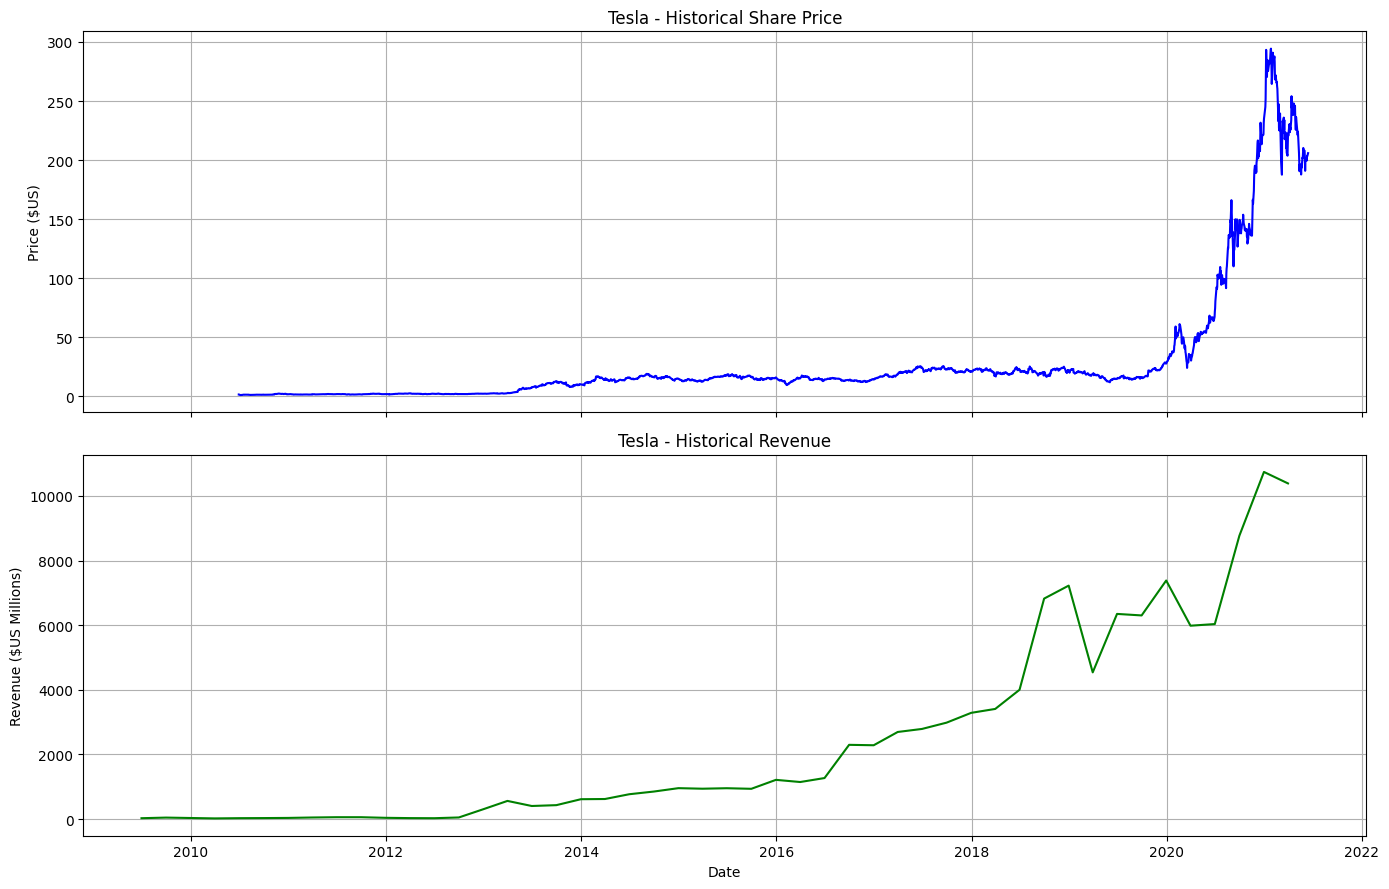

In [ ]:
make_graph(
    tesla_data,
    tesla_revenue,
    "Tesla"
)

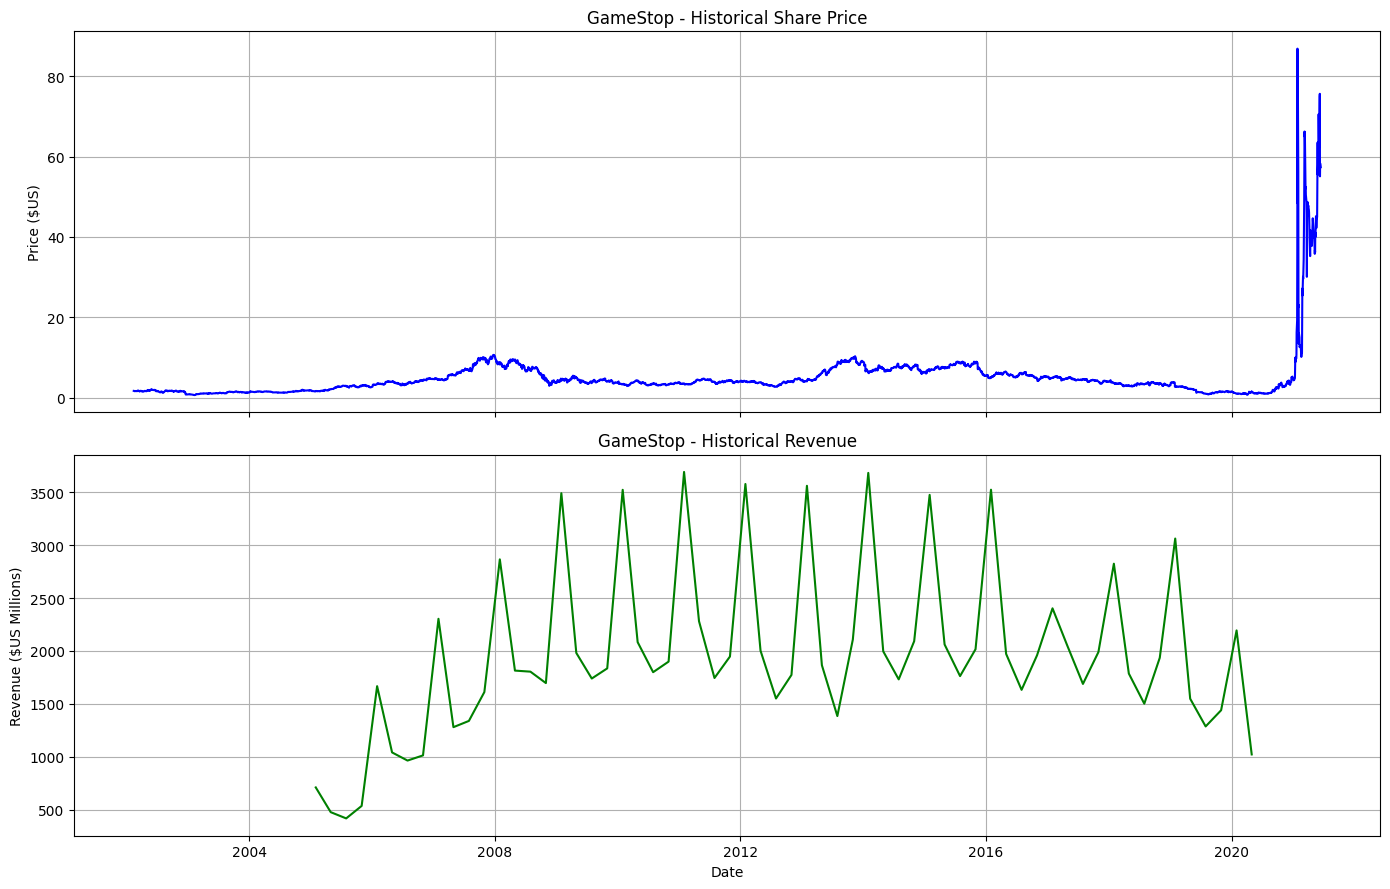

In [ ]:
make_graph(
    gme_data,
    gme_revenue,
    "GameStop"
)

========== FINAL PROJECT VERIFICATION ==========

1. Tesla Stock Data:


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0



2. Tesla Revenue Data:


,Date,Revenue
48,2010-09-30,31.0
49,2010-06-30,28.0
50,2010-03-31,21.0
51,2009-09-30,46.0
52,2009-06-30,27.0



3. GameStop Stock Data:


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716073,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0



4. GameStop Revenue Data:


,Date,Revenue
57,2006-01-31,1667.0
58,2005-10-31,534.0
59,2005-07-31,416.0
60,2005-04-30,475.0
61,2005-01-31,709.0



5. Tesla Dashboard:


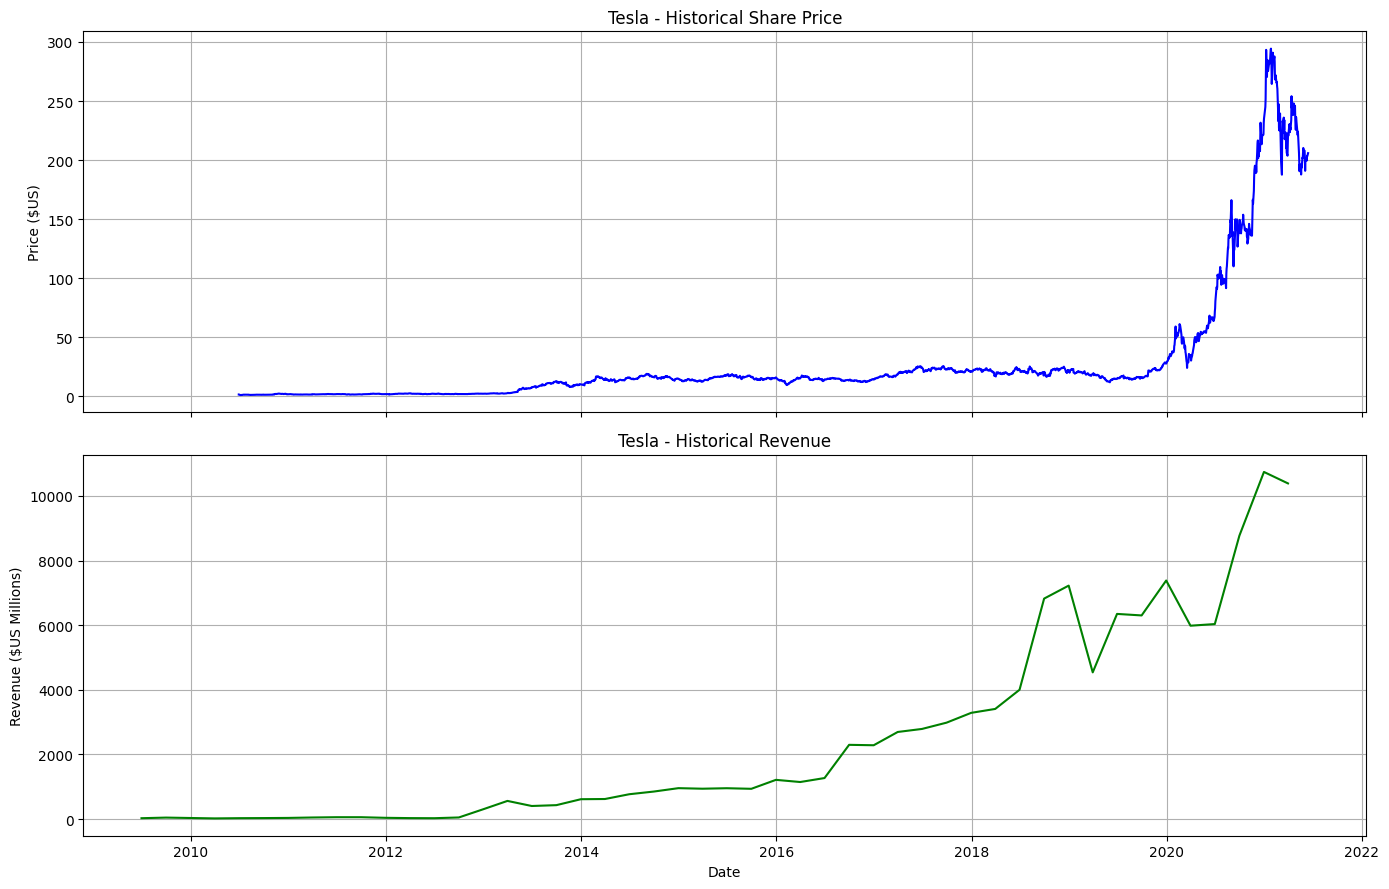


6. GameStop Dashboard:


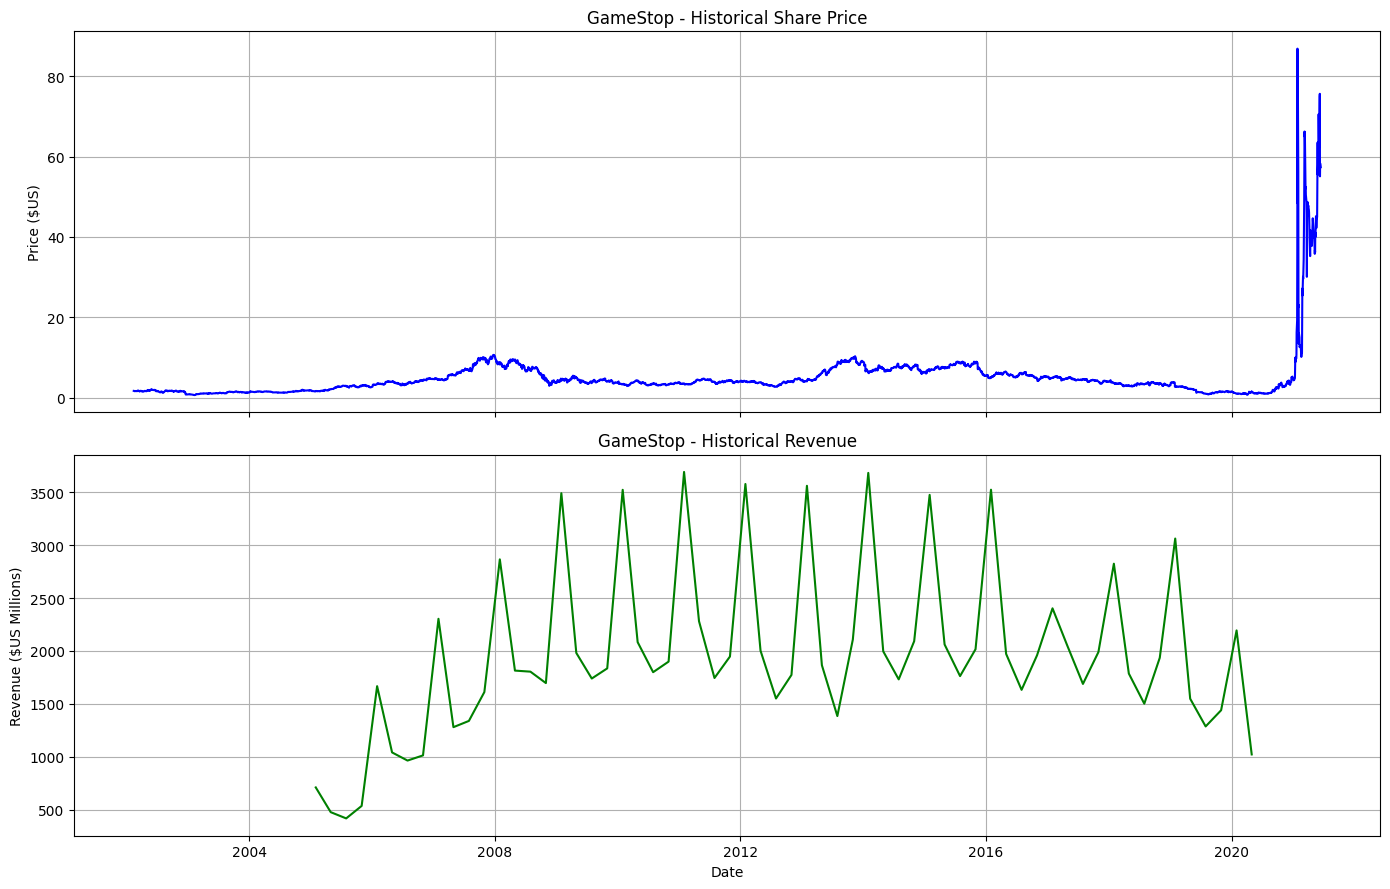


========== PROJECT COMPLETED ==========


In [ ]:
print("========== FINAL PROJECT VERIFICATION ==========")

print("\n1. Tesla Stock Data:")
display(tesla_data.head())

print("\n2. Tesla Revenue Data:")
display(tesla_revenue.tail())

print("\n3. GameStop Stock Data:")
display(gme_data.head())

print("\n4. GameStop Revenue Data:")
display(gme_revenue.tail())

print("\n5. Tesla Dashboard:")
make_graph(tesla_data, tesla_revenue, "Tesla")

print("\n6. GameStop Dashboard:")
make_graph(gme_data, gme_revenue, "GameStop")

print("\n========== PROJECT COMPLETED ==========")